# 02 — Validation de bout en bout : Data loader + Buy & Hold

Ce notebook teste **tout le pipeline** de la couche de données jusqu'au backtest Buy & Hold :

`configuration → téléchargement → validation → sauvegarde → rechargement → Buy & Hold → métriques → graphiques`

Objectif : vérifier, étape par étape et avec des assertions, que chaque brique fonctionne et s'enchaîne correctement. Les cellules réseau (yfinance) gèrent proprement une éventuelle coupure ; les erreurs de logique, d'import ou de calcul, elles, doivent faire échouer le notebook.

> Données : uniquement Yahoo Finance (gratuit, public). Aucune clé API, aucun trading réel.

## 1. Initialisation du projet

But : rendre le notebook exécutable **quel que soit le dossier de travail** (par ex. ouvert depuis `notebooks/` dans VS Code). On remonte l'arborescence jusqu'à trouver la racine (présence de `src/` et `config/`), on l'ajoute au `sys.path` pour que `import src...` fonctionne, et on vérifie les dossiers clés.

In [1]:
import sys
from pathlib import Path


def find_project_root(markers=("src", "config")) -> Path:
    """Remonte les dossiers parents jusqu'à trouver la racine du projet."""
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if all((candidate / m).is_dir() for m in markers):
            return candidate
    raise RuntimeError(
        "Racine du projet introuvable. Ouvre le notebook depuis le dépôt."
    )


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for folder in ["src", "data", "config", "tests"]:
    assert (PROJECT_ROOT / folder).is_dir(), f"Dossier manquant : {folder}"

print("Racine du projet :", PROJECT_ROOT)
print("Dossiers src/data/config/tests : OK")

Racine du projet : C:\Users\degar\OneDrive - De Vinci Higher Education (DVHE)\Perso\Projet Investissement\personal-quant-lab
Dossiers src/data/config/tests : OK


## 2. Imports

On importe les fonctions réellement présentes dans `src/` ainsi que les bibliothèques scientifiques. `%matplotlib inline` garantit l'affichage des graphiques dans le notebook.

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import (
    download_prices,
    save_prices,
    load_prices,
    load_tickers_from_yaml,
    validate_prices,
)
from src.backtest import buy_and_hold, build_equity_curve
from src.metrics import (
    compute_returns,
    compute_drawdown,
    max_drawdown,
    yearly_returns,
    performance_summary,
)
from src.plotting import plot_equity_curve, plot_drawdown

print("Imports OK")

Imports OK


## 3. Test synthétique (sans Internet)

Avant tout appel réseau, on valide la **logique de calcul** sur une petite série de prix connue à l'avance. C'est déterministe et instantané.

Prix `[100, 102, 101, 105, 110]`, capital initial `10 000`. Comme le prix passe de 100 à 110 (+10 %), le capital final attendu est **≈ 11 000**.

In [3]:
dates = pd.date_range("2024-01-01", periods=5, freq="D")
synthetic_prices = pd.Series(
    [100, 102, 101, 105, 110], index=dates, dtype=float, name="SYNTH"
)
INITIAL_CAPITAL = 10_000

synthetic_returns = compute_returns(synthetic_prices)
synthetic_equity = build_equity_curve(synthetic_returns, initial_capital=INITIAL_CAPITAL)
synthetic_bh = buy_and_hold(synthetic_prices, initial_capital=INITIAL_CAPITAL)
synthetic_dd = compute_drawdown(synthetic_bh["Equity Curve"])
synthetic_summary = performance_summary(
    synthetic_bh["Returns"], synthetic_bh["Equity Curve"]
)

print(synthetic_bh)
print()
print(synthetic_summary)

            Prices   Returns  Equity Curve
2024-01-01   100.0       NaN       10000.0
2024-01-02   102.0  0.020000       10200.0
2024-01-03   101.0 -0.009804       10100.0
2024-01-04   105.0  0.039604       10500.0
2024-01-05   110.0  0.047619       11000.0

CAGR               404.265062
Volatility           0.405711
Sharpe              15.127508
Max Drawdown        -0.009804
Best Year            0.100000
Worst Year           0.100000
Final Capital    11000.000000
dtype: float64


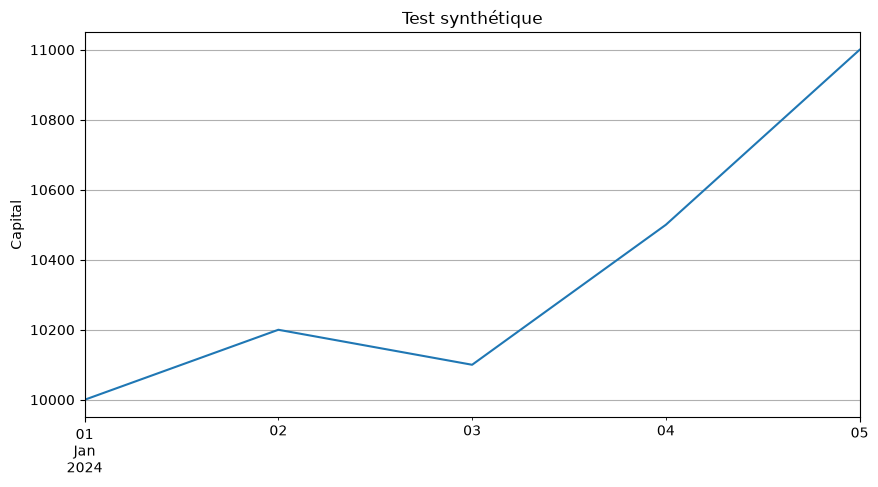

Test synthétique OK — capital final = 11000.0


In [4]:
final_capital = synthetic_bh["Equity Curve"].iloc[-1]

assert np.isclose(final_capital, 11_000, rtol=1e-9), final_capital
assert not synthetic_returns.isna().any()            # pas de NaN après nettoyage
assert (synthetic_dd <= 1e-12).all()                 # drawdown toujours <= 0
assert list(synthetic_bh.columns) == ["Prices", "Returns", "Equity Curve"]
assert (synthetic_bh["Equity Curve"] > 0).all()      # capital toujours positif

fig, ax = plot_equity_curve(synthetic_bh["Equity Curve"], title="Test synthétique")
plt.show()

print("Test synthétique OK — capital final =", round(final_capital, 2))

## 4. Chargement de la configuration YAML

On lit l'univers de tickers depuis `config/assets.yaml` via `load_tickers_from_yaml`, qui aplatit les catégories et supprime les doublons.

In [5]:
tickers = load_tickers_from_yaml(PROJECT_ROOT / "config" / "assets.yaml")
print("Tickers chargés :", tickers)

assert isinstance(tickers, list)
assert len(tickers) > 0
assert len(tickers) == len(set(tickers)), "doublons détectés"
assert all(isinstance(t, str) and t.strip() for t in tickers)

print("Configuration YAML OK —", len(tickers), "tickers uniques")

Tickers chargés : ['CW8.PA', 'EWLD.PA', 'ESE.PA', 'BTC-USD', 'ETH-USD']
Configuration YAML OK — 5 tickers uniques


## 5. Test réel mono-ticker (yfinance)

On télécharge un ETF de référence (idéalement `CW8.PA`, MSCI World éligible PEA) depuis 2020. On vérifie la forme et la qualité du DataFrame.

**Robustesse réseau :** si Yahoo Finance est indisponible, on l'affiche clairement et le drapeau `NETWORK_OK` permet aux étapes suivantes de basculer sur un fichier local déjà enregistré.

In [6]:
BENCHMARK = "CW8.PA" if "CW8.PA" in tickers else tickers[0]
START = "2020-01-01"
print("Benchmark retenu :", BENCHMARK)

Benchmark retenu : CW8.PA


In [7]:
NETWORK_OK = True
mono_prices = None
try:
    mono_prices = download_prices(BENCHMARK, start=START)
except Exception as exc:  # échec réseau / Yahoo indisponible uniquement
    NETWORK_OK = False
    print("ATTENTION — téléchargement mono-ticker impossible :", exc)

if mono_prices is not None:
    print("Premières lignes :")
    print(mono_prices.head())
    print("\nDernières lignes :")
    print(mono_prices.tail())
    print("\nForme :", mono_prices.shape)
    print("Période :", mono_prices.index.min().date(), "→", mono_prices.index.max().date())
    print("Valeurs manquantes :", int(mono_prices.isna().sum().sum()))

    assert isinstance(mono_prices, pd.DataFrame)
    assert not mono_prices.empty
    assert isinstance(mono_prices.index, pd.DatetimeIndex)
    assert mono_prices.index.is_monotonic_increasing        # trié
    assert not mono_prices.index.has_duplicates             # pas de doublon
    assert BENCHMARK in mono_prices.columns
    assert not mono_prices.isna().all().any()               # aucune colonne vide
    print("\nTest mono-ticker OK")

Premières lignes :
                CW8.PA
Date                  
2020-01-02  313.134003
2020-01-03  313.123688
2020-01-06  312.296997
2020-01-07  314.015503
2020-01-08  314.540405

Dernières lignes :
                CW8.PA
Date                  
2026-07-02  681.979980
2026-07-03  684.520020
2026-07-06  687.739990
2026-07-07  682.530029
2026-07-08  677.539978

Forme : (1669, 1)
Période : 2020-01-02 → 2026-07-08
Valeurs manquantes : 0

Test mono-ticker OK


## 6. Test réel multi-tickers (gestion du MultiIndex)

Avec plusieurs tickers, yfinance renvoie des colonnes **MultiIndex** `(type_de_prix, ticker)`. `download_prices` doit en extraire les clôtures et produire une colonne par ticker. On choisit deux ETF cotés les mêmes jours.

> **Note calendrier :** on ne mélange pas ETF et crypto dans ce test. Les ETF européens ne cotent **pas le week-end**, alors que la crypto cote **7 j/7**. Mélanger les deux introduirait des lignes partiellement vides (jours où seule la crypto a un prix) et brouillerait la validation. L'alignement de calendriers différents se traite plus tard, au niveau de la stratégie.

In [8]:
etf_candidates = [t for t in tickers if t.endswith(".PA")]
MULTI = etf_candidates[:2] if len(etf_candidates) >= 2 else [BENCHMARK]
print("Tickers multi :", MULTI)

multi_prices = None
if NETWORK_OK and len(MULTI) >= 2:
    try:
        multi_prices = download_prices(MULTI, start=START)
    except Exception as exc:
        print("ATTENTION — téléchargement multi-ticker impossible :", exc)

if multi_prices is not None:
    print(multi_prices.head())
    print("\nForme :", multi_prices.shape)

    assert set(multi_prices.columns) == set(MULTI)          # colonnes = tickers
    assert multi_prices.shape[1] == multi_prices.select_dtypes("number").shape[1]
    assert not multi_prices.isna().all().any()              # aucune colonne vide
    assert multi_prices.index.is_monotonic_increasing       # trié
    assert not multi_prices.index.has_duplicates            # pas de doublon
    print("\nTest multi-ticker OK — MultiIndex correctement géré")

Tickers multi : ['CW8.PA', 'EWLD.PA']


                CW8.PA  EWLD.PA
Date                           
2020-01-02  313.134003      NaN
2020-01-03  313.123688      NaN
2020-01-06  312.296997      NaN
2020-01-07  314.015503      NaN
2020-01-08  314.540405      NaN

Forme : (1669, 2)

Test multi-ticker OK — MultiIndex correctement géré


## 7. Validation des données

On choisit la source à conserver (priorité au multi-tickers, qui contient le benchmark), puis on la passe explicitement dans `validate_prices` : `DatetimeIndex`, tri chronologique, suppression des doublons et des colonnes entièrement vides. **Aucun forward-fill silencieux.** On affiche une synthèse de qualité.

In [9]:
if multi_prices is not None:
    prices = multi_prices.copy()
elif mono_prices is not None:
    prices = mono_prices.copy()
else:
    # Mode dégradé hors-ligne : réutiliser un fichier déjà enregistré s'il existe
    fallback = PROJECT_ROOT / "data" / "processed" / "validation_prices.csv"
    if fallback.exists():
        print("Hors-ligne — utilisation du fichier local :", fallback.name)
        prices = load_prices(fallback)
    else:
        raise RuntimeError(
            "Aucune donnée disponible (réseau KO et aucun fichier local). "
            "Relance le notebook avec une connexion Internet."
        )

prices = validate_prices(prices)

quality = pd.Series(
    {
        "DatetimeIndex": isinstance(prices.index, pd.DatetimeIndex),
        "Trié chronologiquement": prices.index.is_monotonic_increasing,
        "Sans date dupliquée": not prices.index.has_duplicates,
        "Nb colonnes": prices.shape[1],
        "Nb lignes": prices.shape[0],
        "NaN restants": int(prices.isna().sum().sum()),
        "Tout numérique": bool(prices.dtypes.map(pd.api.types.is_numeric_dtype).all()),
        "Prix minimum": float(prices.min().min()),
    }
)
print(quality)

assert prices.min().min() > 0, "prix négatif ou nul détecté"
print("\nValidation des données OK")

DatetimeIndex                  True
Trié chronologiquement         True
Sans date dupliquée            True
Nb colonnes                       2
Nb lignes                      1669
NaN restants                   1080
Tout numérique                 True
Prix minimum              27.623943
dtype: object

Validation des données OK


## 8. Sauvegarde et rechargement CSV (roundtrip)

On écrit les prix validés dans `data/processed/validation_prices.csv`, on recharge via `load_prices`, puis on compare. Le CSV stocke du texte : on tolère une infime différence de précision (`rtol`).

In [10]:
CSV_PATH = PROJECT_ROOT / "data" / "processed" / "validation_prices.csv"
save_prices(prices, CSV_PATH)
assert CSV_PATH.exists()

prices_csv = load_prices(CSV_PATH)
pd.testing.assert_frame_equal(prices, prices_csv, check_exact=False, rtol=1e-6, atol=1e-8)

assert list(prices_csv.columns) == list(prices.columns)   # colonnes préservées
assert isinstance(prices_csv.index, pd.DatetimeIndex)     # DatetimeIndex préservé
assert prices_csv.index.is_monotonic_increasing           # ordre chronologique
assert not prices_csv.empty

ROUNDTRIP_CSV_OK = True
print("Roundtrip CSV OK →", CSV_PATH.relative_to(PROJECT_ROOT))

Roundtrip CSV OK → data\processed\validation_prices.csv


## 9. Sauvegarde et rechargement Parquet (optionnel)

Parquet a besoin d'un moteur (`pyarrow` ou `fastparquet`). S'il est absent, on **n'échoue pas** : le test est marqué `IGNORÉ` et on affiche la commande d'installation.

In [11]:
import importlib.util

HAS_PARQUET = (
    importlib.util.find_spec("pyarrow") is not None
    or importlib.util.find_spec("fastparquet") is not None
)

ROUNDTRIP_PARQUET = "IGNORÉ"
if HAS_PARQUET:
    PARQUET_PATH = PROJECT_ROOT / "data" / "processed" / "validation_prices.parquet"
    save_prices(prices, PARQUET_PATH)
    prices_pq = load_prices(PARQUET_PATH)
    pd.testing.assert_frame_equal(prices, prices_pq, check_exact=False, rtol=1e-6, atol=1e-8)
    ROUNDTRIP_PARQUET = "OK"
    print("Roundtrip Parquet OK →", PARQUET_PATH.relative_to(PROJECT_ROOT))
else:
    print("pyarrow non installé — test Parquet IGNORÉ. Pour l'activer :")
    print("    python -m pip install pyarrow")

Roundtrip Parquet OK → data\processed\validation_prices.parquet


## 10. Pipeline Buy & Hold complet

On repart des **données rechargées depuis le disque** (`prices_csv`), pas du résultat réseau : c'est ce qui valide toute la chaîne de persistance. On isole la série du benchmark et on lance `buy_and_hold`.

In [12]:
data = prices_csv                       # données rechargées depuis le CSV
benchmark = data[BENCHMARK].dropna()    # dropna local, uniquement pour cette série
assert not benchmark.empty

bh = buy_and_hold(benchmark, initial_capital=INITIAL_CAPITAL)
print("Premières lignes :")
print(bh.head())
print("\nDernières lignes :")
print(bh.tail())

price_initial = benchmark.iloc[0]
price_final = benchmark.iloc[-1]
capital_final = bh["Equity Curve"].iloc[-1]
total_return = capital_final / INITIAL_CAPITAL - 1

print("\nCapital initial :", f"{INITIAL_CAPITAL:,.0f}")
print("Capital final   :", f"{capital_final:,.2f}")
print("Rendement total :", f"{total_return:.2%}")
print("Période         :", benchmark.index.min().date(), "→", benchmark.index.max().date())

Premières lignes :
                Prices   Returns  Equity Curve
Date                                          
2020-01-02  313.134003       NaN  10000.000000
2020-01-03  313.123688 -0.000033   9999.670590
2020-01-06  312.296997 -0.002640   9973.270050
2020-01-07  314.015503  0.005503  10028.150895
2020-01-08  314.540405  0.001672  10044.913761

Dernières lignes :
                Prices   Returns  Equity Curve
Date                                          
2026-07-02  681.979980 -0.004772  21779.173600
2026-07-03  684.520020  0.003725  21860.290280
2026-07-06  687.739990  0.004704  21963.120719
2026-07-07  682.530029 -0.007575  21796.739525
2026-07-08  677.539978 -0.007311  21637.381192

Capital initial : 10,000
Capital final   : 21,637.38
Rendement total : 116.37%
Période         : 2020-01-02 → 2026-07-08


## 11. Vérification mathématique du Buy & Hold

Sans frais, un Buy & Hold vaut exactement :

`capital_final = capital_initial × prix_final / prix_initial`

On compare la théorie au résultat de `buy_and_hold`.

In [13]:
expected_final = INITIAL_CAPITAL * price_final / price_initial

assert np.isclose(capital_final, expected_final, rtol=1e-9), (capital_final, expected_final)
print(f"Vérification OK : {capital_final:,.2f} ≈ {expected_final:,.2f}")

Vérification OK : 21,637.38 ≈ 21,637.38


## 12. Métriques de performance

On calcule le résumé (`performance_summary`) et on l'affiche lisiblement : les métriques pertinentes en pourcentage. **Les valeurs numériques d'origine ne sont pas modifiées** — le formatage ne sert qu'à l'affichage.

In [14]:
returns = bh["Returns"]
equity = bh["Equity Curve"]
summary = performance_summary(returns, equity, periods_per_year=252, risk_free_rate=0.0)

pct_keys = {"CAGR", "Volatility", "Max Drawdown", "Best Year", "Worst Year"}
formatted = {}
for key, value in summary.items():
    if key in pct_keys:
        formatted[key] = f"{value:.2%}"
    elif key == "Final Capital":
        formatted[key] = f"{value:,.2f}"
    else:
        formatted[key] = f"{value:.3f}"

print(pd.Series(formatted).to_string())

assert summary["Volatility"] >= 0
assert summary["Max Drawdown"] <= 1e-12
assert np.isclose(summary["Final Capital"], equity.iloc[-1], rtol=1e-9)
for key in ["CAGR", "Volatility", "Sharpe", "Max Drawdown", "Best Year", "Worst Year", "Final Capital"]:
    assert key in summary.index
print("\nMétriques OK")

CAGR                12.37%
Volatility          16.36%
Sharpe               0.795
Max Drawdown       -33.62%
Best Year           32.34%
Worst Year         -13.74%
Final Capital    21,637.38

Métriques OK


## 13. Rendements annuels

Rendements par année civile, avec un graphique en barres et une ligne à zéro (vert = année positive, rouge = négative).

Date
2020-12-31      4.97 %
2021-12-31     32.34 %
2022-12-31    -13.74 %
2023-12-31     19.63 %
2024-12-31     27.09 %
2025-12-31      6.62 %
2026-12-31      11.4 %
Freq: YE-DEC, Name: Returns, dtype: object


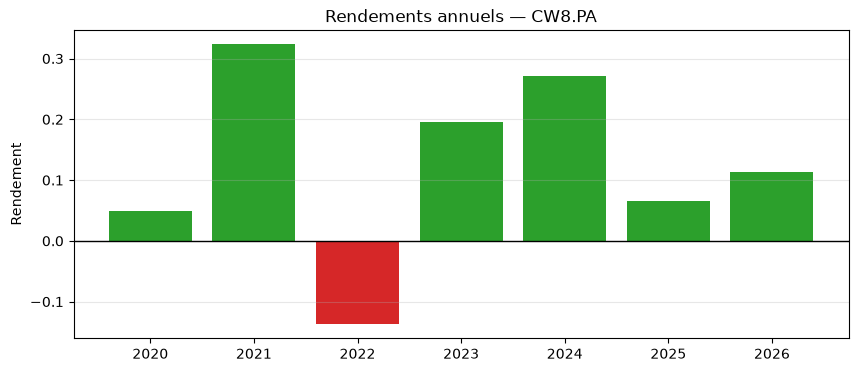

In [15]:
annual = yearly_returns(returns)
print((annual * 100).round(2).astype(str) + " %")

assert not annual.empty
assert not annual.isna().any()

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["#2ca02c" if v >= 0 else "#d62728" for v in annual.values]
ax.bar(annual.index.year, annual.values, color=colors)
ax.axhline(0, color="black", linewidth=1)
ax.set_title(f"Rendements annuels — {BENCHMARK}")
ax.set_ylabel("Rendement")
ax.grid(True, axis="y", alpha=0.3)
plt.show()

## 14. Graphiques

1. Courbe de capital, 2. Drawdown (via `src/plotting.py`), puis 4. une comparaison **prix normalisé à 10 000** vs **equity curve**. Sans frais, les deux courbes doivent se superposer.

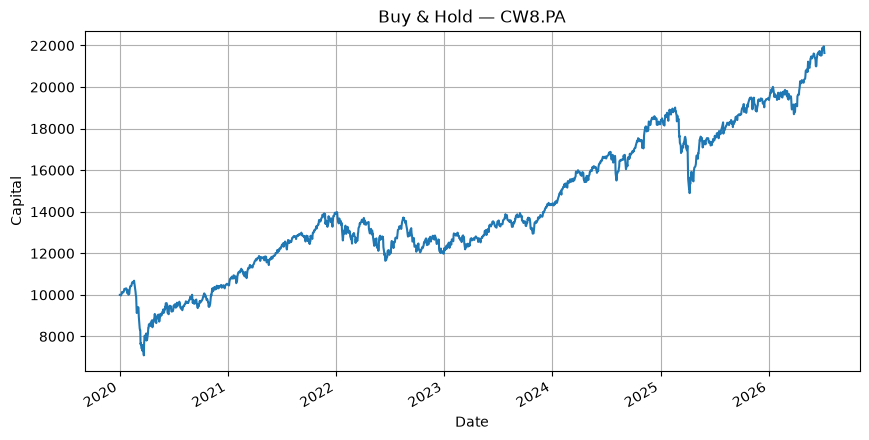

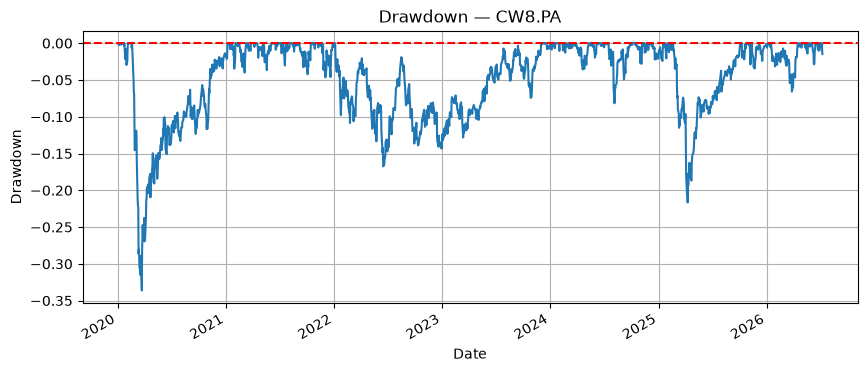

In [16]:
fig1, ax1 = plot_equity_curve(equity, title=f"Buy & Hold — {BENCHMARK}")
plt.show()

fig2, ax2 = plot_drawdown(equity, title=f"Drawdown — {BENCHMARK}")
plt.show()

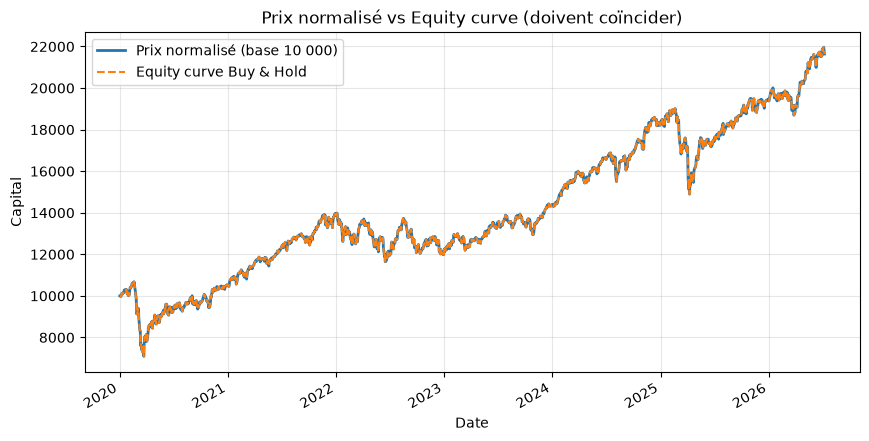

Écart maximum prix normalisé vs equity : 3.64e-12


In [17]:
normalized_price = benchmark / benchmark.iloc[0] * INITIAL_CAPITAL

fig, ax = plt.subplots(figsize=(10, 5))
normalized_price.plot(ax=ax, label="Prix normalisé (base 10 000)", linewidth=2)
equity.plot(ax=ax, label="Equity curve Buy & Hold", linestyle="--")
ax.set_title("Prix normalisé vs Equity curve (doivent coïncider)")
ax.set_ylabel("Capital")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

max_gap = (normalized_price - equity).abs().max()
assert np.isclose(max_gap, 0.0, atol=1e-6), max_gap
print("Écart maximum prix normalisé vs equity :", f"{max_gap:.2e}")

## 15. Tableau final de validation

Récapitulatif de tous les contrôles obligatoires. Le Parquet apparaît comme `OK` **ou** `IGNORÉ`. Une assertion finale fait échouer la cellule si un contrôle obligatoire échoue.

In [18]:
cleaned_returns = returns.dropna()

checks = {
    "Données chargées": not data.empty,
    "Index temporel valide": isinstance(data.index, pd.DatetimeIndex),
    "Dates triées": data.index.is_monotonic_increasing,
    "Aucune date dupliquée": not data.index.has_duplicates,
    "Benchmark non vide": not benchmark.empty,
    "Backtest non vide": not bh.empty,
    "Rendements (nettoyés) sans NaN": (not cleaned_returns.empty)
        and (not cleaned_returns.isna().any()),
    "Equity curve sans NaN": not equity.isna().any(),
    "Capital toujours positif": bool((equity > 0).all()),
    "Drawdown toujours <= 0": bool((compute_drawdown(equity) <= 1e-12).all()),
    "Capital final = théorique": bool(np.isclose(capital_final, expected_final, rtol=1e-9)),
    "Métriques requises présentes": all(
        k in summary.index
        for k in ["CAGR", "Volatility", "Sharpe", "Max Drawdown",
                  "Best Year", "Worst Year", "Final Capital"]
    ),
    "Roundtrip CSV validé": bool(ROUNDTRIP_CSV_OK),
}

print(f"{'Contrôle':38s} Statut")
print("-" * 50)
failed = []
for name, ok in checks.items():
    status = "OK" if ok else "ÉCHEC"
    print(f"{name:38s} {status}")
    if not ok:
        failed.append(name)

# Parquet : optionnel (OK ou IGNORÉ)
print(f"{'Roundtrip Parquet':38s} {ROUNDTRIP_PARQUET}")

assert not failed, f"Contrôles obligatoires en échec : {failed}"
print("\nPipeline data loader + Buy & Hold validé de bout en bout.")

Contrôle                               Statut
--------------------------------------------------
Données chargées                       OK
Index temporel valide                  OK
Dates triées                           OK
Aucune date dupliquée                  OK
Benchmark non vide                     OK
Backtest non vide                      OK
Rendements (nettoyés) sans NaN         OK
Equity curve sans NaN                  OK
Capital toujours positif               OK
Drawdown toujours <= 0                 OK
Capital final = théorique              OK
Métriques requises présentes           OK
Roundtrip CSV validé                   OK
Roundtrip Parquet                      OK

Pipeline data loader + Buy & Hold validé de bout en bout.
